# Myocardial Infarction Risk Prediction Using Machine Learning

## Mini Project

This project develops a machine learning pipeline for predicting myocardial infarction risk using clinical patient data.

The project includes data preprocessing, exploratory data analysis, dimensionality reduction using PCA, unsupervised clustering using K-Means and DBSCAN, comparison of multiple supervised machine learning models, hyperparameter tuning, and a final patient risk prediction system.

# Predicting Myocardial Infarction Risk Using Machine Learning

### Machine Learning Mini Project

**Dataset:** Heart Attack Analysis & Prediction Dataset

**Techniques:**
- Exploratory Data Analysis
- Principal Component Analysis (PCA)
- K-Means Clustering
- DBSCAN
- Logistic Regression
- Gradient Boosting
- Support Vector Machine
- Random Forest
- Bagging
- Neural Network

**Objective:**  
To develop machine learning models for predicting myocardial infarction risk and explore patterns in the patient data using supervised and unsupervised learning.

In [1]:
print("Myocardial Infarction ML Project")
print("Google Colab is working!")

Myocardial Infarction ML Project
Google Colab is working!


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    adjusted_rand_score,
    silhouette_score,
    roc_curve
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    GradientBoostingClassifier,
    RandomForestClassifier,
    BaggingClassifier
)
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [11]:
from google.colab import files

uploaded = files.upload()

Saving heart.csv to heart (3).csv


In [12]:
df = pd.read_csv("heart.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (1025, 14)


In [13]:
# Check the dataset
print("Original dataset shape:", df.shape)

print("\nNumber of duplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

print("\nDataset shape after removing duplicates:", df.shape)

Original dataset shape: (1025, 14)

Number of duplicate rows: 723

Dataset shape after removing duplicates: (302, 14)


In [14]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 302 entries, 0 to 301
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       302 non-null    int64  
 1   sex       302 non-null    int64  
 2   cp        302 non-null    int64  
 3   trestbps  302 non-null    int64  
 4   chol      302 non-null    int64  
 5   fbs       302 non-null    int64  
 6   restecg   302 non-null    int64  
 7   thalach   302 non-null    int64  
 8   exang     302 non-null    int64  
 9   oldpeak   302 non-null    float64
 10  slope     302 non-null    int64  
 11  ca        302 non-null    int64  
 12  thal      302 non-null    int64  
 13  target    302 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.2 KB


In [16]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


In [17]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,302.00000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000
mean,54.42053,0.682119,0.963576,131.602649,246.500000,0.149007,0.526490,149.569536,0.327815,1.043046,1.397351,0.718543,2.314570,0.543046
std,9.04797,0.466426,1.032044,17.563394,51.753489,0.356686,0.526027,22.903527,0.470196,1.161452,0.616274,1.006748,0.613026,0.498970
min,29.00000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.00000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.250000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.50000,1.000000,1.000000,130.000000,240.500000,0.000000,1.000000,152.500000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.00000,1.000000,2.000000,140.000000,274.750000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.00000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [18]:
print("Target distribution:")
print(df["target"].value_counts())

print("\nTarget percentage:")
print(df["target"].value_counts(normalize=True) * 100)

Target distribution:
target
1    164
0    138
Name: count, dtype: int64

Target percentage:
target
1    54.304636
0    45.695364
Name: proportion, dtype: float64


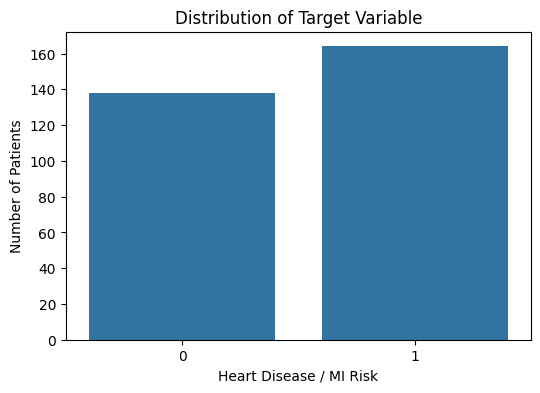

In [19]:
plt.figure(figsize=(6, 4))

sns.countplot(x="target", data=df)

plt.title("Distribution of Target Variable")
plt.xlabel("Heart Disease / MI Risk")
plt.ylabel("Number of Patients")

plt.show()

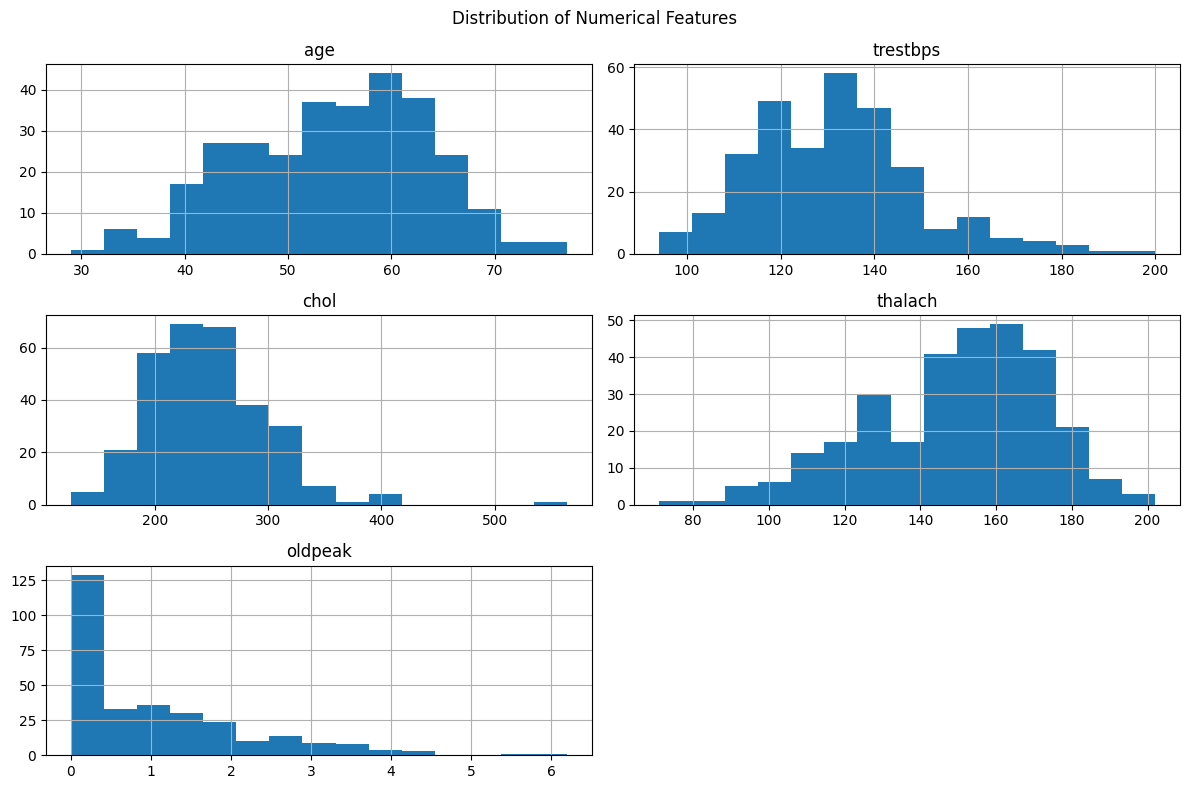

In [20]:
numerical_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

df[numerical_features].hist(
    figsize=(12, 8),
    bins=15
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

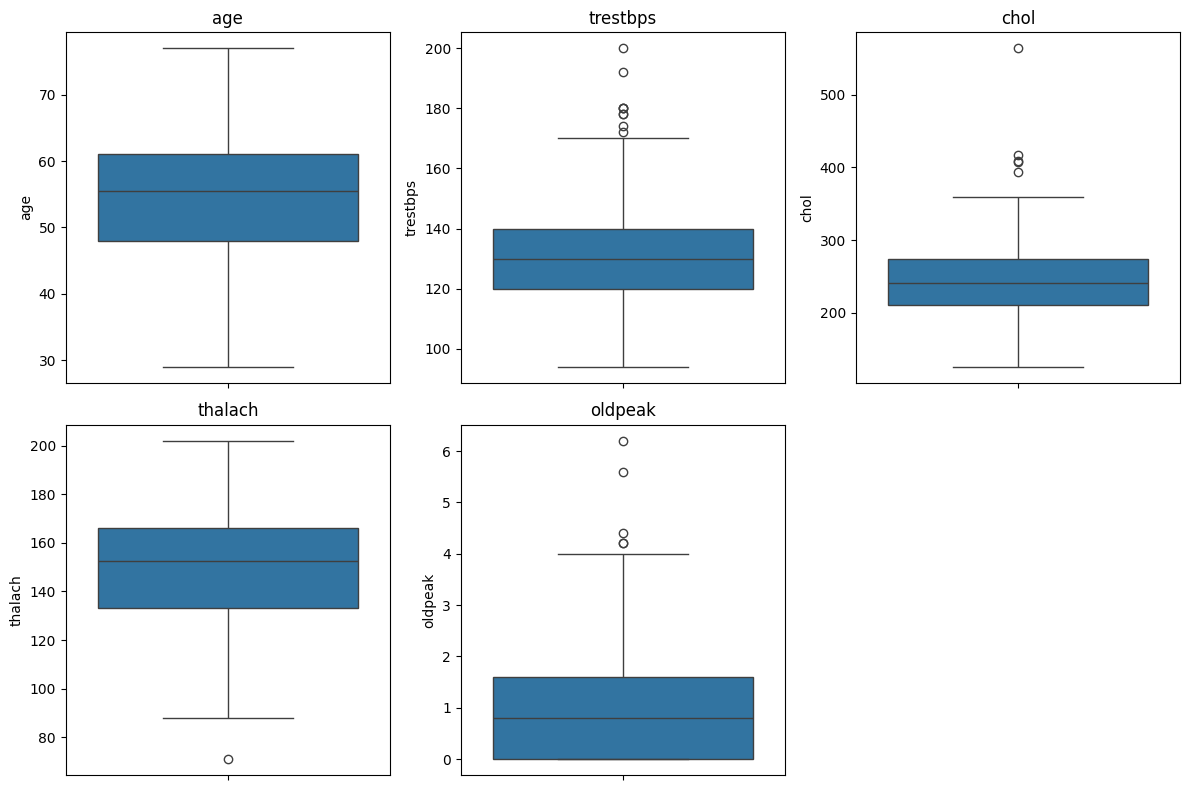

In [21]:
plt.figure(figsize=(12, 8))

for i, feature in enumerate(numerical_features, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[feature])
    plt.title(feature)

plt.tight_layout()
plt.show()

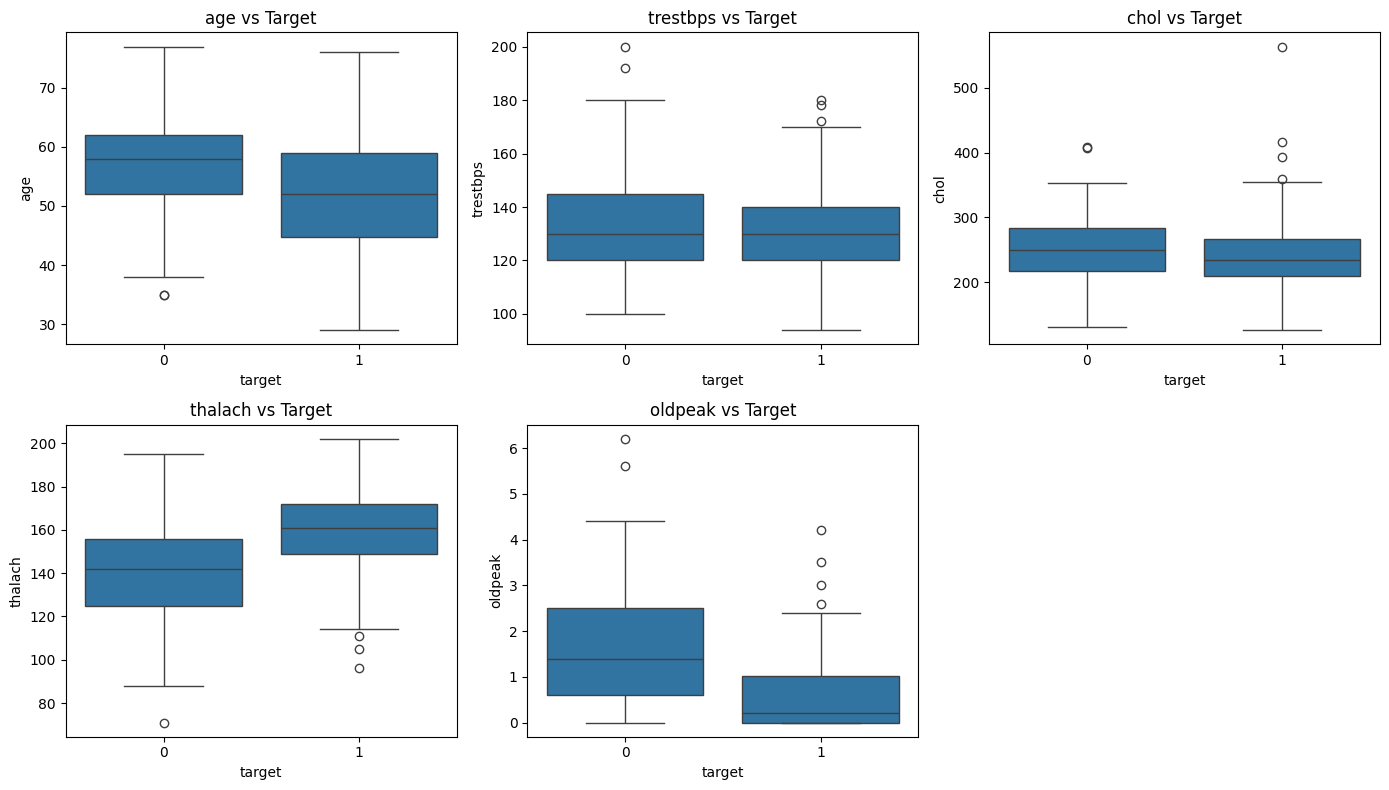

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for i, feature in enumerate(numerical_features):
    sns.boxplot(
        x="target",
        y=feature,
        data=df,
        ax=axes.flatten()[i]
    )
    axes.flatten()[i].set_title(f"{feature} vs Target")

axes.flatten()[-1].axis("off")

plt.tight_layout()
plt.show()

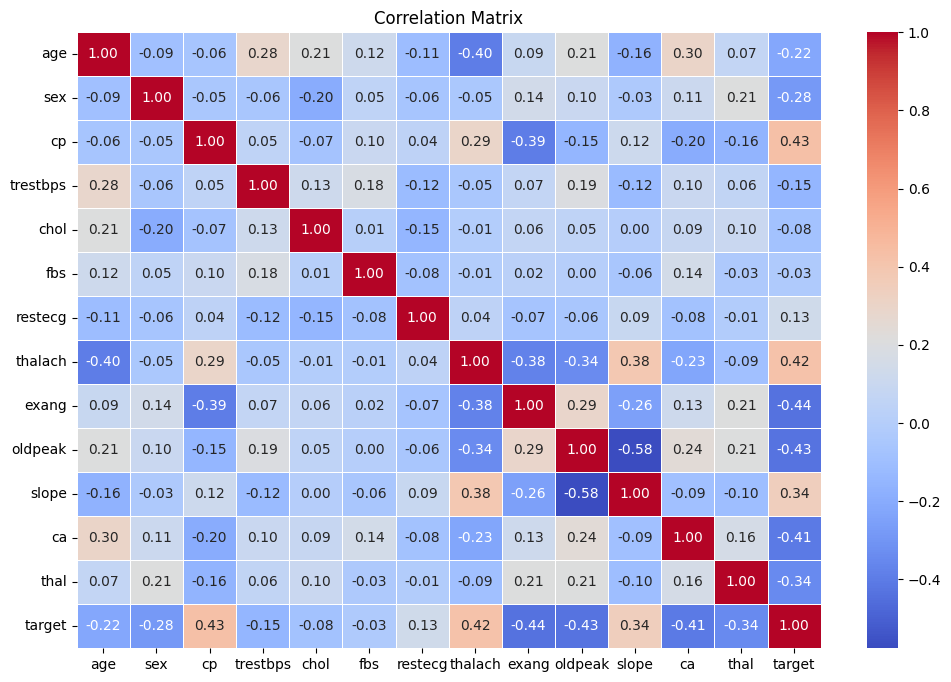

In [23]:
plt.figure(figsize=(12, 8))

correlation_matrix = df.corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Matrix")
plt.show()

In [24]:
target_correlation = (
    df.corr()["target"]
    .sort_values(ascending=False)
)

print(target_correlation)

target      1.000000
cp          0.432080
thalach     0.419955
slope       0.343940
restecg     0.134874
fbs        -0.026826
chol       -0.081437
trestbps   -0.146269
age        -0.221476
sex        -0.283609
thal       -0.343101
ca         -0.408992
oldpeak    -0.429146
exang      -0.435601
Name: target, dtype: float64


In [25]:
df.to_csv("heart_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Shape:", df.shape)

Cleaned dataset saved successfully!
Shape: (302, 14)


In [26]:
# Separate features and target

X = df.drop("target", axis=1)
y = df["target"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (302, 13)
Target shape: (302,)


In [27]:
# Standardize features

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (302, 13)


In [28]:
# Apply PCA with 2 components

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("PCA shape:", X_pca.shape)

PCA shape: (302, 2)


In [29]:
print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal variance explained:")
print(pca.explained_variance_ratio_.sum())

Explained variance ratio:
[0.21313479 0.11859478]

Total variance explained:
0.33172957822141036


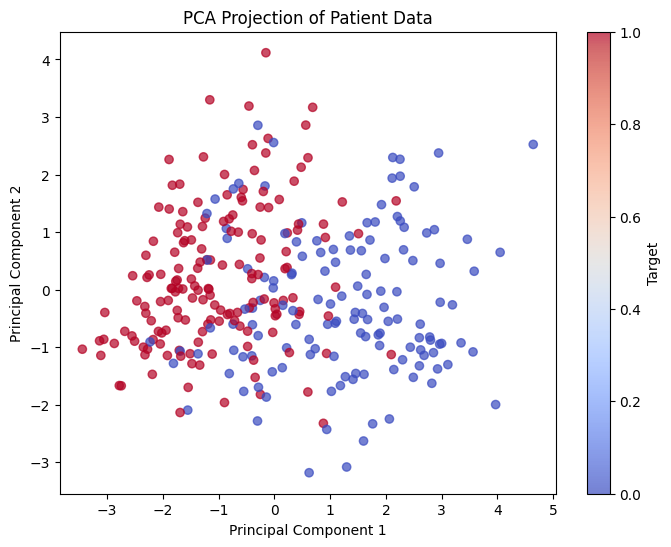

In [30]:
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap="coolwarm",
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Projection of Patient Data")

plt.colorbar(scatter, label="Target")

plt.show()

In [31]:
# K-Means clustering

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_pca)

print("K-Means cluster counts:")
print(pd.Series(kmeans_labels).value_counts())

K-Means cluster counts:
0    196
1    106
Name: count, dtype: int64


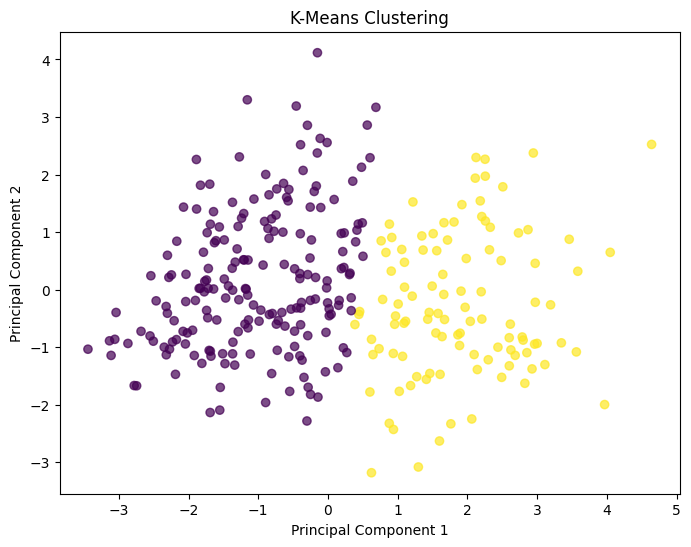

In [32]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering")

plt.show()

In [33]:
kmeans_ari = adjusted_rand_score(y, kmeans_labels)

print("K-Means Adjusted Rand Index:", round(kmeans_ari, 4))

K-Means Adjusted Rand Index: 0.377


In [34]:
k_values = range(2, 11)

ari_scores = []
silhouette_scores = []

for k in k_values:
    kmeans_temp = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans_temp.fit_predict(X_pca)

    ari_scores.append(adjusted_rand_score(y, labels))
    silhouette_scores.append(silhouette_score(X_pca, labels))

print("K values:", list(k_values))
print("ARI scores:", [round(x, 4) for x in ari_scores])
print("Silhouette scores:", [round(x, 4) for x in silhouette_scores])

K values: [2, 3, 4, 5, 6, 7, 8, 9, 10]
ARI scores: [0.377, 0.2739, 0.2302, 0.183, 0.1384, 0.128, 0.1134, 0.1008, 0.0871]
Silhouette scores: [np.float64(0.4227), np.float64(0.3819), np.float64(0.3655), np.float64(0.3842), np.float64(0.3664), np.float64(0.3652), np.float64(0.3694), np.float64(0.3761), np.float64(0.37)]


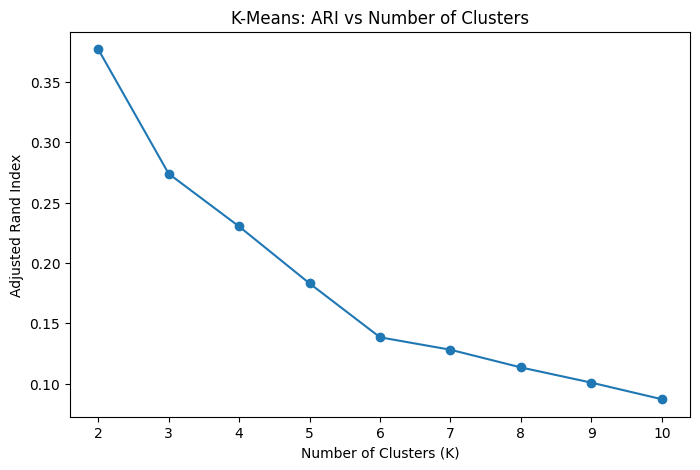

In [35]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    ari_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Adjusted Rand Index")
plt.title("K-Means: ARI vs Number of Clusters")
plt.xticks(list(k_values))

plt.show()

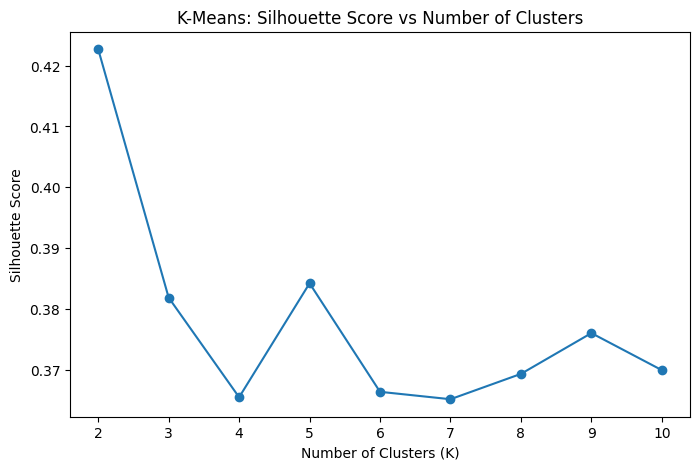

In [36]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("K-Means: Silhouette Score vs Number of Clusters")
plt.xticks(list(k_values))

plt.show()

#DBSCAN Clustering

In [37]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=0.5,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(X_pca)

print("DBSCAN cluster labels:")
print(np.unique(dbscan_labels))

print("\nCluster counts:")
print(pd.Series(dbscan_labels).value_counts())

DBSCAN cluster labels:
[-1  0]

Cluster counts:
 0    275
-1     27
Name: count, dtype: int64


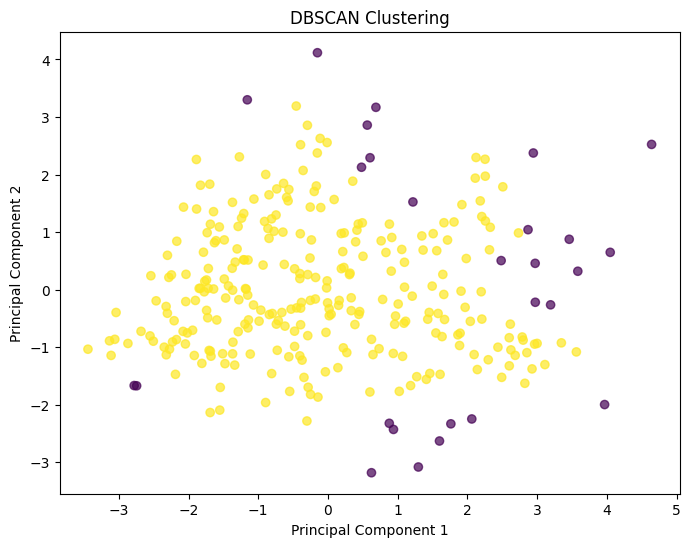

In [38]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=dbscan_labels,
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("DBSCAN Clustering")

plt.show()

In [39]:
unique_labels = set(dbscan_labels)

n_clusters = len(unique_labels - {-1})
n_noise = list(dbscan_labels).count(-1)

print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)

Number of clusters: 1
Number of noise points: 27


In [40]:
dbscan_ari = adjusted_rand_score(y, dbscan_labels)

print("DBSCAN Adjusted Rand Index:", round(dbscan_ari, 4))

DBSCAN Adjusted Rand Index: 0.0115


In [41]:
eps_values = np.arange(0.2, 2.1, 0.1)

dbscan_results = []

for eps in eps_values:
    model = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = model.fit_predict(X_pca)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

    if n_clusters > 1:
        ari = adjusted_rand_score(y, labels)
        silhouette = silhouette_score(X_pca, labels)
    else:
        ari = np.nan
        silhouette = np.nan

    noise_points = np.sum(labels == -1)

    dbscan_results.append([
        eps,
        n_clusters,
        noise_points,
        ari,
        silhouette
    ])

dbscan_results = pd.DataFrame(
    dbscan_results,
    columns=[
        "eps",
        "clusters",
        "noise_points",
        "ARI",
        "silhouette"
    ]
)

dbscan_results

,eps,clusters,noise_points,ARI,silhouette
0,0.2,10,230,0.000016,-0.264622
1,0.3,12,114,0.065319,-0.120392
2,0.4,4,45,0.024579,-0.024809
3,0.5,1,27,NaN,NaN
4,0.6,1,18,NaN,NaN
5,0.7,2,7,0.007255,0.187214
6,0.8,1,4,NaN,NaN
7,0.9,1,3,NaN,NaN
8,1.0,1,2,NaN,NaN
9,1.1,1,1,NaN,NaN


In [42]:
dbscan_results.sort_values(
    by="ARI",
    ascending=False
).head(10)

,eps,clusters,noise_points,ARI,silhouette
1,0.3,12,114,0.065319,-0.120392
2,0.4,4,45,0.024579,-0.024809
5,0.7,2,7,0.007255,0.187214
0,0.2,10,230,0.000016,-0.264622
3,0.5,1,27,NaN,NaN
4,0.6,1,18,NaN,NaN
6,0.8,1,4,NaN,NaN
7,0.9,1,3,NaN,NaN
8,1.0,1,2,NaN,NaN
9,1.1,1,1,NaN,NaN


In [43]:
dbscan_results.sort_values(
    by="silhouette",
    ascending=False
).head(10)

,eps,clusters,noise_points,ARI,silhouette
5,0.7,2,7,0.007255,0.187214
2,0.4,4,45,0.024579,-0.024809
1,0.3,12,114,0.065319,-0.120392
0,0.2,10,230,0.000016,-0.264622
3,0.5,1,27,NaN,NaN
4,0.6,1,18,NaN,NaN
6,0.8,1,4,NaN,NaN
7,0.9,1,3,NaN,NaN
8,1.0,1,2,NaN,NaN
9,1.1,1,1,NaN,NaN


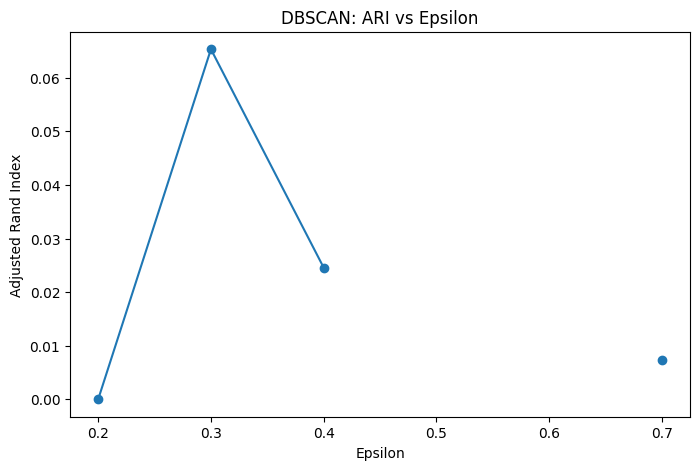

In [44]:
plt.figure(figsize=(8, 5))

plt.plot(
    dbscan_results["eps"],
    dbscan_results["ARI"],
    marker="o"
)

plt.xlabel("Epsilon")
plt.ylabel("Adjusted Rand Index")
plt.title("DBSCAN: ARI vs Epsilon")

plt.show()

In [45]:
clustering_comparison = pd.DataFrame({
    "Algorithm": [
        "K-Means",
        "DBSCAN"
    ],
    "ARI": [
        kmeans_ari,
        dbscan_ari
    ]
})

clustering_comparison

,Algorithm,ARI
0,K-Means,0.377044
1,DBSCAN,0.011541


In [46]:
print(
    clustering_comparison.sort_values(
        by="ARI",
        ascending=False
    )
)

  Algorithm       ARI
0   K-Means  0.377044
1    DBSCAN  0.011541


In [47]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop("target", axis=1)
y = df["target"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (241, 13)
Testing data: (61, 13)


In [48]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training and testing data standardized successfully!")

Training and testing data standardized successfully!


In [51]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_scaled, y_train)

lr_predictions = lr_model.predict(X_test_scaled)

print("Logistic Regression Results")
print("----------------------------")
print("Accuracy:", accuracy_score(y_test, lr_predictions))
print("\nClassification Report:")
print(classification_report(y_test, lr_predictions))

Logistic Regression Results
----------------------------
Accuracy: 0.8032786885245902

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.75      0.78        28
           1       0.80      0.85      0.82        33

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.80      0.80      0.80        61



In [52]:
results = {}

def evaluate_model(name, model, X_test_data, y_test_data):
    predictions = model.predict(X_test_data)

    accuracy = accuracy_score(y_test_data, predictions)
    precision = precision_score(y_test_data, predictions)
    recall = recall_score(y_test_data, predictions)
    f1 = f1_score(y_test_data, predictions)

    results[name] = {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    }

    print(f"\n{name}")
    print("-" * len(name))
    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1 Score : {f1:.4f}")

In [53]:
evaluate_model(
    "Logistic Regression",
    lr_model,
    X_test_scaled,
    y_test
)


Logistic Regression
-------------------
Accuracy : 0.8033
Precision: 0.8000
Recall   : 0.8485
F1 Score : 0.8235


In [54]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

evaluate_model(
    "Random Forest",
    rf_model,
    X_test,
    y_test
)


Random Forest
-------------
Accuracy : 0.7541
Precision: 0.7647
Recall   : 0.7879
F1 Score : 0.7761


In [55]:
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

gb_model.fit(X_train, y_train)

evaluate_model(
    "Gradient Boosting",
    gb_model,
    X_test,
    y_test
)


Gradient Boosting
-----------------
Accuracy : 0.7213
Precision: 0.7353
Recall   : 0.7576
F1 Score : 0.7463


In [56]:
svm_linear = SVC(
    kernel="linear",
    probability=True,
    random_state=42
)

svm_linear.fit(X_train_scaled, y_train)

evaluate_model(
    "SVM Linear",
    svm_linear,
    X_test_scaled,
    y_test
)


SVM Linear
----------
Accuracy : 0.8197
Precision: 0.8056
Recall   : 0.8788
F1 Score : 0.8406


In [57]:
svm_rbf = SVC(
    kernel="rbf",
    probability=True,
    random_state=42
)

svm_rbf.fit(X_train_scaled, y_train)

evaluate_model(
    "SVM RBF",
    svm_rbf,
    X_test_scaled,
    y_test
)


SVM RBF
-------
Accuracy : 0.7705
Precision: 0.7714
Recall   : 0.8182
F1 Score : 0.7941


In [58]:
svm_poly = SVC(
    kernel="poly",
    degree=3,
    probability=True,
    random_state=42
)

svm_poly.fit(X_train_scaled, y_train)

evaluate_model(
    "SVM Polynomial",
    svm_poly,
    X_test_scaled,
    y_test
)


SVM Polynomial
--------------
Accuracy : 0.8197
Precision: 0.7895
Recall   : 0.9091
F1 Score : 0.8451


In [59]:
elastic_net = LogisticRegression(
    penalty="elasticnet",
    solver="saga",
    l1_ratio=0.5,
    max_iter=5000,
    random_state=42
)

elastic_net.fit(X_train_scaled, y_train)

evaluate_model(
    "Elastic Net",
    elastic_net,
    X_test_scaled,
    y_test
)


Elastic Net
-----------
Accuracy : 0.8033
Precision: 0.8000
Recall   : 0.8485
F1 Score : 0.8235


In [60]:
bagging_model = BaggingClassifier(
    n_estimators=100,
    random_state=42
)

bagging_model.fit(X_train, y_train)

evaluate_model(
    "Bagging",
    bagging_model,
    X_test,
    y_test
)


Bagging
-------
Accuracy : 0.7705
Precision: 0.7714
Recall   : 0.8182
F1 Score : 0.7941


In [61]:
nn_model = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation="relu",
    solver="adam",
    max_iter=1000,
    random_state=42
)

nn_model.fit(X_train_scaled, y_train)

evaluate_model(
    "Neural Network",
    nn_model,
    X_test_scaled,
    y_test
)


Neural Network
--------------
Accuracy : 0.7541
Precision: 0.7647
Recall   : 0.7879
F1 Score : 0.7761


In [62]:
results_df = pd.DataFrame(results).T

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

results_df

,Accuracy,Precision,Recall,F1 Score
SVM Polynomial,0.819672,0.789474,0.909091,0.845070
SVM Linear,0.819672,0.805556,0.878788,0.840580
Logistic Regression,0.803279,0.800000,0.848485,0.823529
Elastic Net,0.803279,0.800000,0.848485,0.823529
SVM RBF,0.770492,0.771429,0.818182,0.794118
Bagging,0.770492,0.771429,0.818182,0.794118
Random Forest,0.754098,0.764706,0.787879,0.776119
Neural Network,0.754098,0.764706,0.787879,0.776119
Gradient Boosting,0.721311,0.735294,0.757576,0.746269


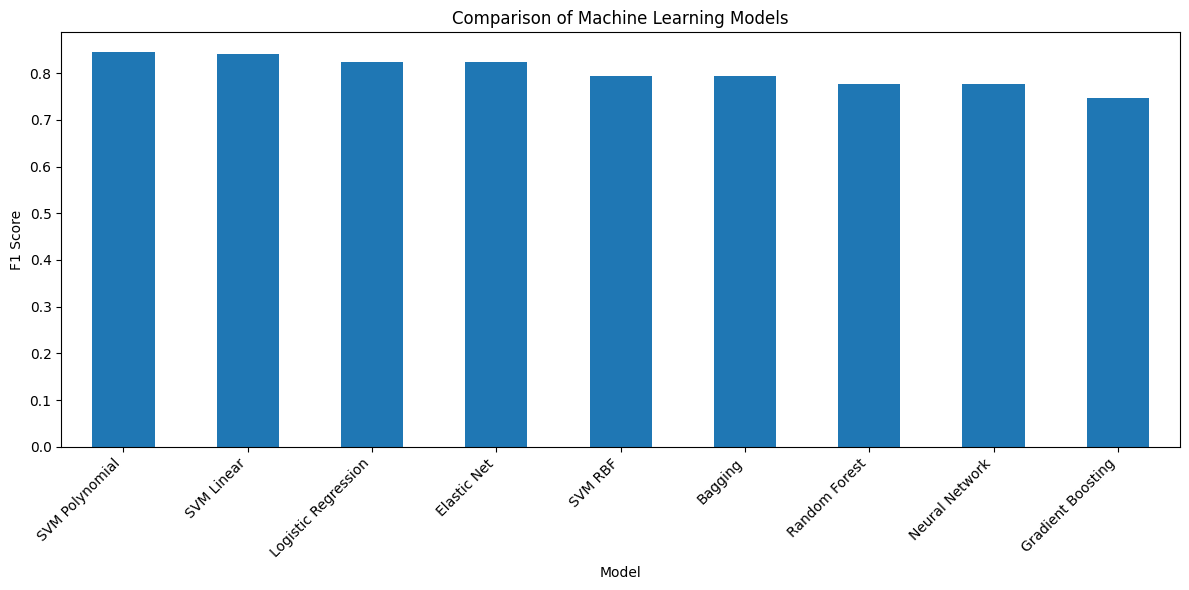

In [63]:
plt.figure(figsize=(12, 6))

results_df["F1 Score"].plot(
    kind="bar"
)

plt.title("Comparison of Machine Learning Models")
plt.xlabel("Model")
plt.ylabel("F1 Score")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

Confusion Matrix:
[[20  8]
 [ 3 30]]


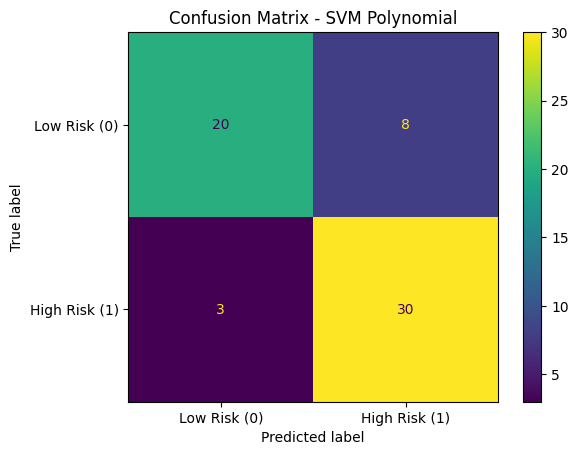

In [64]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predictions from the best model so far
svm_poly_predictions = svm_poly.predict(X_test_scaled)

cm = confusion_matrix(y_test, svm_poly_predictions)

print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low Risk (0)", "High Risk (1)"]
).plot()

plt.title("Confusion Matrix - SVM Polynomial")
plt.show()

In [65]:
# Calculate ROC-AUC for all models

roc_scores = {}

model_data = {
    "Logistic Regression": (lr_model, X_test_scaled),
    "Random Forest": (rf_model, X_test),
    "Gradient Boosting": (gb_model, X_test),
    "SVM Linear": (svm_linear, X_test_scaled),
    "SVM RBF": (svm_rbf, X_test_scaled),
    "SVM Polynomial": (svm_poly, X_test_scaled),
    "Elastic Net": (elastic_net, X_test_scaled),
    "Bagging": (bagging_model, X_test),
    "Neural Network": (nn_model, X_test_scaled)
}

for name, (model, test_data) in model_data.items():

    probabilities = model.predict_proba(test_data)[:, 1]

    auc = roc_auc_score(y_test, probabilities)

    roc_scores[name] = auc

roc_scores

{'Logistic Regression': np.float64(0.8712121212121212),
 'Random Forest': np.float64(0.8701298701298701),
 'Gradient Boosting': np.float64(0.8257575757575758),
 'SVM Linear': np.float64(0.8690476190476191),
 'SVM RBF': np.float64(0.841991341991342),
 'SVM Polynomial': np.float64(0.8701298701298702),
 'Elastic Net': np.float64(0.8722943722943723),
 'Bagging': np.float64(0.8371212121212122),
 'Neural Network': np.float64(0.8322510822510824)}

In [66]:
results_df["AUROC"] = pd.Series(roc_scores)

results_df = results_df.sort_values(
    by="AUROC",
    ascending=False
)

results_df

,Accuracy,Precision,Recall,F1 Score,AUROC
Elastic Net,0.803279,0.800000,0.848485,0.823529,0.872294
Logistic Regression,0.803279,0.800000,0.848485,0.823529,0.871212
SVM Polynomial,0.819672,0.789474,0.909091,0.845070,0.870130
Random Forest,0.754098,0.764706,0.787879,0.776119,0.870130
SVM Linear,0.819672,0.805556,0.878788,0.840580,0.869048
SVM RBF,0.770492,0.771429,0.818182,0.794118,0.841991
Bagging,0.770492,0.771429,0.818182,0.794118,0.837121
Neural Network,0.754098,0.764706,0.787879,0.776119,0.832251
Gradient Boosting,0.721311,0.735294,0.757576,0.746269,0.825758


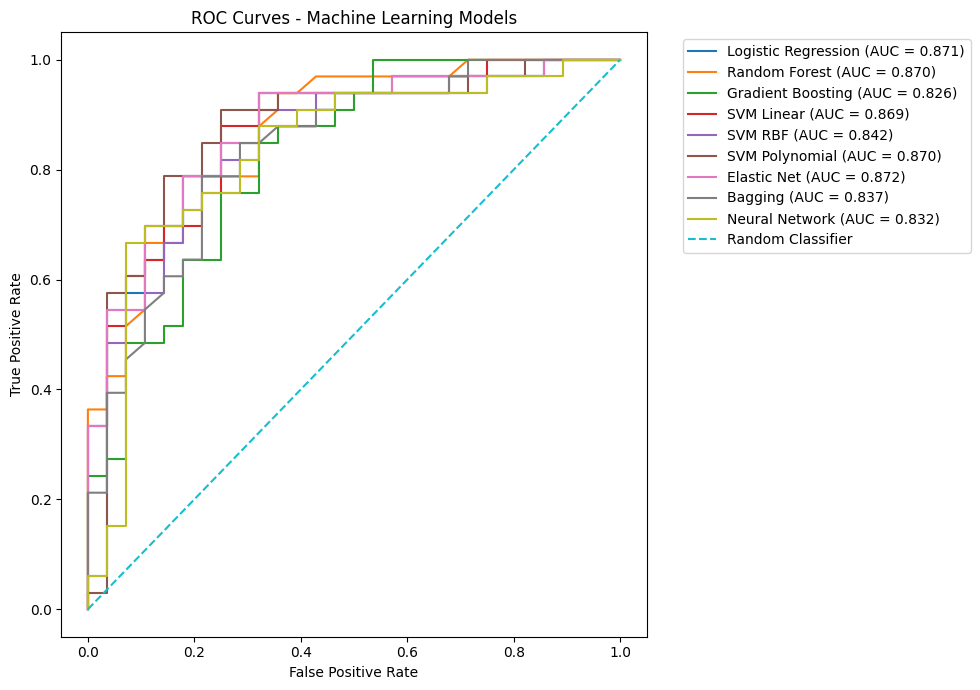

In [67]:
plt.figure(figsize=(10, 7))

for name, (model, test_data) in model_data.items():

    probabilities = model.predict_proba(test_data)[:, 1]

    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities
    )

    auc = roc_auc_score(
        y_test,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Machine Learning Models")
plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [68]:
results_df.round(4)

,Accuracy,Precision,Recall,F1 Score,AUROC
Elastic Net,0.8033,0.8000,0.8485,0.8235,0.8723
Logistic Regression,0.8033,0.8000,0.8485,0.8235,0.8712
SVM Polynomial,0.8197,0.7895,0.9091,0.8451,0.8701
Random Forest,0.7541,0.7647,0.7879,0.7761,0.8701
SVM Linear,0.8197,0.8056,0.8788,0.8406,0.8690
SVM RBF,0.7705,0.7714,0.8182,0.7941,0.8420
Bagging,0.7705,0.7714,0.8182,0.7941,0.8371
Neural Network,0.7541,0.7647,0.7879,0.7761,0.8323
Gradient Boosting,0.7213,0.7353,0.7576,0.7463,0.8258


In [69]:
print("Best model by F1 Score:")
print(
    results_df["F1 Score"].idxmax(),
    "→",
    results_df["F1 Score"].max()
)

print("\nBest model by AUROC:")
print(
    results_df["AUROC"].idxmax(),
    "→",
    results_df["AUROC"].max()
)

print("\nBest model by Recall:")
print(
    results_df["Recall"].idxmax(),
    "→",
    results_df["Recall"].max()
)

Best model by F1 Score:
SVM Polynomial → 0.8450704225352113

Best model by AUROC:
Elastic Net → 0.8722943722943723

Best model by Recall:
SVM Polynomial → 0.9090909090909091


In [70]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-fold stratified cross-validation ready.")

5-fold stratified cross-validation ready.


In [71]:
svm_poly_tuned = SVC(
    kernel="poly",
    probability=True,
    random_state=42
)

svm_poly_params = {
    "C": [0.1, 1, 10, 100],
    "degree": [2, 3, 4, 5],
    "gamma": ["scale", "auto"]
}

svm_poly_grid = GridSearchCV(
    estimator=svm_poly_tuned,
    param_grid=svm_poly_params,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1
)

svm_poly_grid.fit(X_train_scaled, y_train)

print("Best SVM Polynomial parameters:")
print(svm_poly_grid.best_params_)

print("\nBest cross-validation AUROC:")
print(round(svm_poly_grid.best_score_, 4))

Best SVM Polynomial parameters:
{'C': 0.1, 'degree': 3, 'gamma': 'auto'}

Best cross-validation AUROC:
0.9228


In [72]:
best_svm_poly = svm_poly_grid.best_estimator_

svm_tuned_prob = best_svm_poly.predict_proba(X_test_scaled)[:, 1]
svm_tuned_pred = best_svm_poly.predict(X_test_scaled)

print("Tuned SVM Polynomial")
print("--------------------")
print("Accuracy :", round(accuracy_score(y_test, svm_tuned_pred), 4))
print("Precision:", round(precision_score(y_test, svm_tuned_pred), 4))
print("Recall   :", round(recall_score(y_test, svm_tuned_pred), 4))
print("F1 Score :", round(f1_score(y_test, svm_tuned_pred), 4))
print("AUROC    :", round(roc_auc_score(y_test, svm_tuned_prob), 4))

Tuned SVM Polynomial
--------------------
Accuracy : 0.7541
Precision: 0.6957
Recall   : 0.9697
F1 Score : 0.8101
AUROC    : 0.8442


In [73]:
elastic_tuned = LogisticRegression(
    penalty="elasticnet",
    solver="saga",
    max_iter=5000,
    random_state=42
)

elastic_params = {
    "C": [0.01, 0.1, 1, 10, 100],
    "l1_ratio": [0.0, 0.25, 0.5, 0.75, 1.0]
}

elastic_grid = GridSearchCV(
    estimator=elastic_tuned,
    param_grid=elastic_params,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1
)

elastic_grid.fit(X_train_scaled, y_train)

print("Best Elastic Net parameters:")
print(elastic_grid.best_params_)

print("\nBest cross-validation AUROC:")
print(round(elastic_grid.best_score_, 4))

Best Elastic Net parameters:
{'C': 0.01, 'l1_ratio': 0.0}

Best cross-validation AUROC:
0.917


In [74]:
best_elastic = elastic_grid.best_estimator_

elastic_tuned_prob = best_elastic.predict_proba(X_test_scaled)[:, 1]
elastic_tuned_pred = best_elastic.predict(X_test_scaled)

print("Tuned Elastic Net")
print("-----------------")
print("Accuracy :", round(accuracy_score(y_test, elastic_tuned_pred), 4))
print("Precision:", round(precision_score(y_test, elastic_tuned_pred), 4))
print("Recall   :", round(recall_score(y_test, elastic_tuned_pred), 4))
print("F1 Score :", round(f1_score(y_test, elastic_tuned_pred), 4))
print("AUROC    :", round(roc_auc_score(y_test, elastic_tuned_prob), 4))

Tuned Elastic Net
-----------------
Accuracy : 0.8033
Precision: 0.7838
Recall   : 0.8788
F1 Score : 0.8286
AUROC    : 0.881


In [75]:
lr_tuned = LogisticRegression(
    max_iter=5000,
    random_state=42
)

lr_params = {
    "C": [0.01, 0.1, 1, 10, 100],
    "solver": ["liblinear", "lbfgs"]
}

lr_grid = GridSearchCV(
    estimator=lr_tuned,
    param_grid=lr_params,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1
)

lr_grid.fit(X_train_scaled, y_train)

print("Best Logistic Regression parameters:")
print(lr_grid.best_params_)

print("\nBest cross-validation AUROC:")
print(round(lr_grid.best_score_, 4))

Best Logistic Regression parameters:
{'C': 0.01, 'solver': 'liblinear'}

Best cross-validation AUROC:
0.917


In [76]:
best_lr = lr_grid.best_estimator_

lr_tuned_prob = best_lr.predict_proba(X_test_scaled)[:, 1]
lr_tuned_pred = best_lr.predict(X_test_scaled)

print("Tuned Logistic Regression")
print("-------------------------")
print("Accuracy :", round(accuracy_score(y_test, lr_tuned_pred), 4))
print("Precision:", round(precision_score(y_test, lr_tuned_pred), 4))
print("Recall   :", round(recall_score(y_test, lr_tuned_pred), 4))
print("F1 Score :", round(f1_score(y_test, lr_tuned_pred), 4))
print("AUROC    :", round(roc_auc_score(y_test, lr_tuned_prob), 4))

Tuned Logistic Regression
-------------------------
Accuracy : 0.8033
Precision: 0.8
Recall   : 0.8485
F1 Score : 0.8235
AUROC    : 0.881


In [77]:
tuned_results = pd.DataFrame({
    "Model": [
        "Tuned SVM Polynomial",
        "Tuned Elastic Net",
        "Tuned Logistic Regression"
    ],
    "Accuracy": [
        accuracy_score(y_test, svm_tuned_pred),
        accuracy_score(y_test, elastic_tuned_pred),
        accuracy_score(y_test, lr_tuned_pred)
    ],
    "Precision": [
        precision_score(y_test, svm_tuned_pred),
        precision_score(y_test, elastic_tuned_pred),
        precision_score(y_test, lr_tuned_pred)
    ],
    "Recall": [
        recall_score(y_test, svm_tuned_pred),
        recall_score(y_test, elastic_tuned_pred),
        recall_score(y_test, lr_tuned_pred)
    ],
    "F1 Score": [
        f1_score(y_test, svm_tuned_pred),
        f1_score(y_test, elastic_tuned_pred),
        f1_score(y_test, lr_tuned_pred)
    ],
    "AUROC": [
        roc_auc_score(y_test, svm_tuned_prob),
        roc_auc_score(y_test, elastic_tuned_prob),
        roc_auc_score(y_test, lr_tuned_prob)
    ]
})

tuned_results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,AUROC
0,Tuned SVM Polynomial,0.7541,0.6957,0.9697,0.8101,0.8442
1,Tuned Elastic Net,0.8033,0.7838,0.8788,0.8286,0.8810
2,Tuned Logistic Regression,0.8033,0.8000,0.8485,0.8235,0.8810


Final Model: Tuned Elastic Net

Confusion Matrix:
[[20  8]
 [ 4 29]]


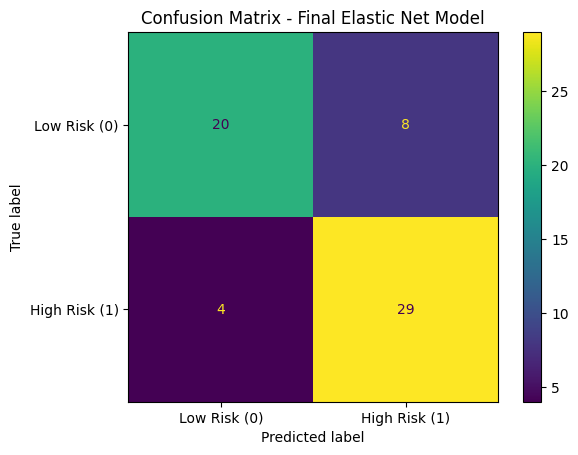

In [78]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Final model predictions
final_model = best_elastic

final_predictions = final_model.predict(X_test_scaled)
final_probabilities = final_model.predict_proba(X_test_scaled)[:, 1]

# Confusion matrix
cm_final = confusion_matrix(y_test, final_predictions)

print("Final Model: Tuned Elastic Net")
print("\nConfusion Matrix:")
print(cm_final)

ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=["Low Risk (0)", "High Risk (1)"]
).plot()

plt.title("Confusion Matrix - Final Elastic Net Model")
plt.show()

In [79]:
print("Final Model Classification Report")
print("-----------------------------------")

print(
    classification_report(
        y_test,
        final_predictions,
        target_names=["Low Risk", "High Risk"]
    )
)

Final Model Classification Report
-----------------------------------
              precision    recall  f1-score   support

    Low Risk       0.83      0.71      0.77        28
   High Risk       0.78      0.88      0.83        33

    accuracy                           0.80        61
   macro avg       0.81      0.80      0.80        61
weighted avg       0.81      0.80      0.80        61



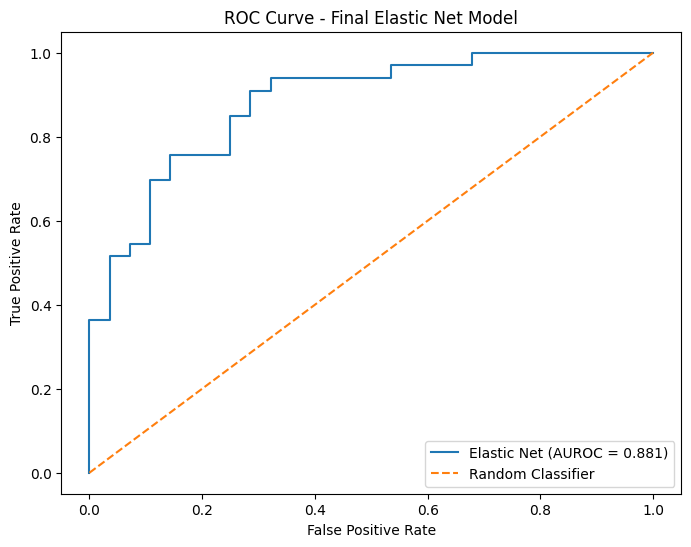

Final AUROC: 0.881


In [80]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(
    y_test,
    final_probabilities
)

final_auc = roc_auc_score(
    y_test,
    final_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Elastic Net (AUROC = {final_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Final Elastic Net Model")
plt.legend()

plt.show()

print("Final AUROC:", round(final_auc, 4))

In [81]:
final_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "AUROC"
    ],
    "Value": [
        accuracy_score(y_test, final_predictions),
        precision_score(y_test, final_predictions),
        recall_score(y_test, final_predictions),
        f1_score(y_test, final_predictions),
        final_auc
    ]
})

final_metrics["Value"] = final_metrics["Value"].round(4)

final_metrics

,Metric,Value
0,Accuracy,0.8033
1,Precision,0.7838
2,Recall,0.8788
3,F1 Score,0.8286
4,AUROC,0.8810


In [82]:
import joblib

joblib.dump(
    final_model,
    "final_elastic_net_model.pkl"
)

joblib.dump(
    scaler,
    "feature_scaler.pkl"
)

print("Final model saved successfully!")
print("Scaler saved successfully!")

Final model saved successfully!
Scaler saved successfully!


In [83]:
feature_names = X.columns.tolist()

print("Feature order:")
for i, feature in enumerate(feature_names, 1):
    print(i, "→", feature)

joblib.dump(
    feature_names,
    "feature_names.pkl"
)

Feature order:
1 → age
2 → sex
3 → cp
4 → trestbps
5 → chol
6 → fbs
7 → restecg
8 → thalach
9 → exang
10 → oldpeak
11 → slope
12 → ca
13 → thal


['feature_names.pkl']

In [84]:
loaded_model = joblib.load(
    "final_elastic_net_model.pkl"
)

loaded_scaler = joblib.load(
    "feature_scaler.pkl"
)

loaded_features = joblib.load(
    "feature_names.pkl"
)

print("Model loaded successfully!")
print("Scaler loaded successfully!")
print("Features loaded successfully!")

print("\nNumber of features:", len(loaded_features))

Model loaded successfully!
Scaler loaded successfully!
Features loaded successfully!

Number of features: 13


In [85]:
def predict_heart_risk(
    age,
    sex,
    cp,
    trestbps,
    chol,
    fbs,
    restecg,
    thalach,
    exang,
    oldpeak,
    slope,
    ca,
    thal
):

    # Create input dataframe in the exact training feature order
    patient_data = pd.DataFrame([[
        age,
        sex,
        cp,
        trestbps,
        chol,
        fbs,
        restecg,
        thalach,
        exang,
        oldpeak,
        slope,
        ca,
        thal
    ]], columns=feature_names)

    # Apply the same scaler used during training
    patient_scaled = loaded_scaler.transform(patient_data)

    # Prediction
    prediction = loaded_model.predict(patient_scaled)[0]

    # Probability of class 1
    probability = loaded_model.predict_proba(patient_scaled)[0][1]

    if prediction == 1:
        result = "Higher predicted risk"
    else:
        result = "Lower predicted risk"

    print("Prediction Result")
    print("-----------------")
    print("Predicted class:", prediction)
    print("Result:", result)
    print(f"Probability of class 1: {probability:.2%}")

    return prediction, probability

In [86]:
# Select one patient from the test set
sample_patient = X_test.iloc[0]

print("Patient input:")
print(sample_patient)

print("\nActual target:", y_test.iloc[0])

Patient input:
age          61.0
sex           0.0
cp            0.0
trestbps    145.0
chol        307.0
fbs           0.0
restecg       0.0
thalach     146.0
exang         1.0
oldpeak       1.0
slope         1.0
ca            0.0
thal          3.0
Name: 24, dtype: float64

Actual target: 0


In [87]:
prediction, probability = predict_heart_risk(
    age=sample_patient["age"],
    sex=sample_patient["sex"],
    cp=sample_patient["cp"],
    trestbps=sample_patient["trestbps"],
    chol=sample_patient["chol"],
    fbs=sample_patient["fbs"],
    restecg=sample_patient["restecg"],
    thalach=sample_patient["thalach"],
    exang=sample_patient["exang"],
    oldpeak=sample_patient["oldpeak"],
    slope=sample_patient["slope"],
    ca=sample_patient["ca"],
    thal=sample_patient["thal"]
)

Prediction Result
-----------------
Predicted class: 0
Result: Lower predicted risk
Probability of class 1: 36.64%


In [88]:
print("Actual class:   ", y_test.iloc[0])
print("Predicted class:", prediction)

if y_test.iloc[0] == prediction:
    print("Prediction is CORRECT")
else:
    print("Prediction is INCORRECT")

Actual class:    0
Predicted class: 0
Prediction is CORRECT


In [89]:
custom_prediction, custom_probability = predict_heart_risk(
    age=55,
    sex=1,
    cp=1,
    trestbps=130,
    chol=240,
    fbs=0,
    restecg=1,
    thalach=150,
    exang=0,
    oldpeak=1.0,
    slope=1,
    ca=0,
    thal=2
)

Prediction Result
-----------------
Predicted class: 1
Result: Higher predicted risk
Probability of class 1: 60.85%


In [90]:
def show_prediction(
    age,
    sex,
    cp,
    trestbps,
    chol,
    fbs,
    restecg,
    thalach,
    exang,
    oldpeak,
    slope,
    ca,
    thal
):

    prediction, probability = predict_heart_risk(
        age,
        sex,
        cp,
        trestbps,
        chol,
        fbs,
        restecg,
        thalach,
        exang,
        oldpeak,
        slope,
        ca,
        thal
    )

    print("\n" + "=" * 45)
    print("       MYOCARDIAL INFARCTION ML")
    print("           RISK PREDICTION")
    print("=" * 45)

    print(f"Predicted Class : {prediction}")
    print(f"Probability     : {probability:.2%}")

    if prediction == 1:
        print("Model Output    : Higher predicted risk")
    else:
        print("Model Output    : Lower predicted risk")

    print("=" * 45)
    print("Note: This is an ML prediction, not a medical diagnosis.")

In [91]:
show_prediction(
    age=55,
    sex=1,
    cp=1,
    trestbps=130,
    chol=240,
    fbs=0,
    restecg=1,
    thalach=150,
    exang=0,
    oldpeak=1.0,
    slope=1,
    ca=0,
    thal=2
)

Prediction Result
-----------------
Predicted class: 1
Result: Higher predicted risk
Probability of class 1: 60.85%

       MYOCARDIAL INFARCTION ML
           RISK PREDICTION
Predicted Class : 1
Probability     : 60.85%
Model Output    : Higher predicted risk
Note: This is an ML prediction, not a medical diagnosis.


# Final Results

The myocardial infarction risk prediction system was evaluated using multiple supervised and unsupervised machine learning techniques.

The unsupervised learning stage included PCA, K-Means clustering, and DBSCAN. The supervised learning stage compared multiple classification algorithms using accuracy, precision, recall, F1-score, and AUROC.

After hyperparameter tuning, Elastic Net Logistic Regression was selected as the final model based on its strong overall performance and highest AUROC among the tuned models.

In [92]:
final_model_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "AUROC"
    ],
    "Score": [
        accuracy_score(y_test, final_predictions),
        precision_score(y_test, final_predictions),
        recall_score(y_test, final_predictions),
        f1_score(y_test, final_predictions),
        final_auc
    ]
})

final_model_summary["Score"] = final_model_summary["Score"].round(4)

final_model_summary

,Metric,Score
0,Accuracy,0.8033
1,Precision,0.7838
2,Recall,0.8788
3,F1 Score,0.8286
4,AUROC,0.8810


In [93]:
model_comparison_final = results_df.copy()

model_comparison_final.round(4)

,Accuracy,Precision,Recall,F1 Score,AUROC
Elastic Net,0.8033,0.8000,0.8485,0.8235,0.8723
Logistic Regression,0.8033,0.8000,0.8485,0.8235,0.8712
SVM Polynomial,0.8197,0.7895,0.9091,0.8451,0.8701
Random Forest,0.7541,0.7647,0.7879,0.7761,0.8701
SVM Linear,0.8197,0.8056,0.8788,0.8406,0.8690
SVM RBF,0.7705,0.7714,0.8182,0.7941,0.8420
Bagging,0.7705,0.7714,0.8182,0.7941,0.8371
Neural Network,0.7541,0.7647,0.7879,0.7761,0.8323
Gradient Boosting,0.7213,0.7353,0.7576,0.7463,0.8258


In [94]:
results_df.round(4).to_csv(
    "all_model_results.csv"
)

tuned_results.round(4).to_csv(
    "tuned_model_results.csv",
    index=False
)

final_model_summary.to_csv(
    "final_model_metrics.csv",
    index=False
)

print("Result files saved successfully!")

Result files saved successfully!


# Conclusion

This project developed a machine learning pipeline for myocardial infarction risk prediction using clinical patient data.

The dataset was cleaned by removing duplicate records and checking for missing values. Exploratory data analysis was performed to understand the distribution and relationships between the clinical variables.

PCA was used for dimensionality reduction, followed by K-Means and DBSCAN clustering to investigate patterns in the patient data.

For supervised classification, multiple machine learning models were trained and evaluated. The models were compared using accuracy, precision, recall, F1-score, and AUROC.

Hyperparameter tuning was then performed on the strongest candidate models. The tuned Elastic Net model achieved an AUROC of approximately 0.881 and was selected as the final model.

The final system can accept patient clinical features and produce a predicted class along with the model's estimated probability for class 1.

The system is intended as a machine learning demonstration and should not be interpreted as a medical diagnosis.

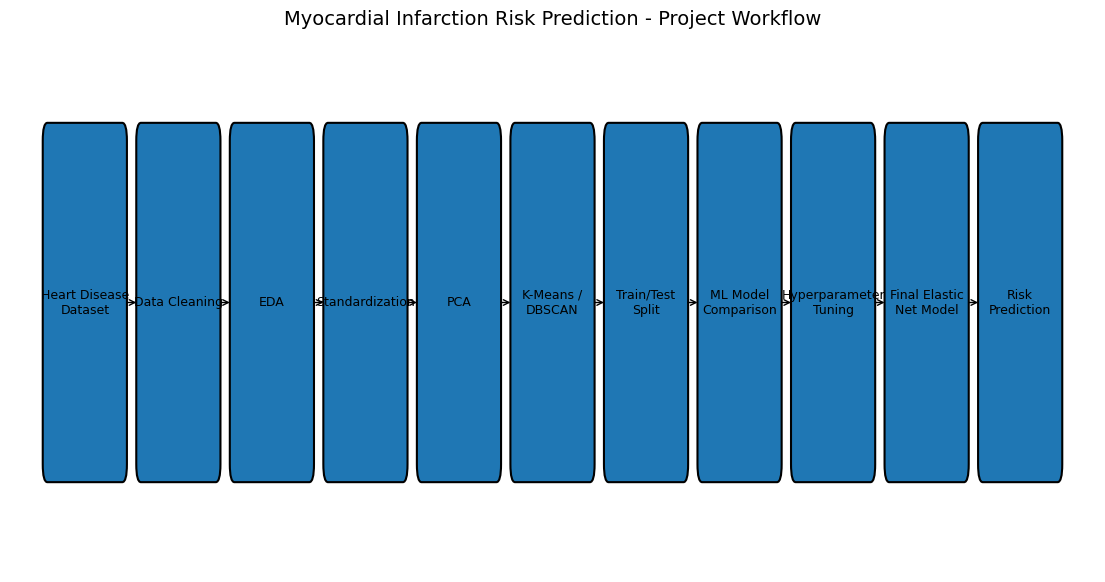

In [95]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(14, 7))

steps = [
    "Heart Disease\nDataset",
    "Data Cleaning",
    "EDA",
    "Standardization",
    "PCA",
    "K-Means /\nDBSCAN",
    "Train/Test\nSplit",
    "ML Model\nComparison",
    "Hyperparameter\nTuning",
    "Final Elastic\nNet Model",
    "Risk\nPrediction"
]

x_positions = range(len(steps))

for i, (x, step) in enumerate(zip(x_positions, steps)):
    box = FancyBboxPatch(
        (x - 0.4, 0.3),
        0.8,
        0.9,
        boxstyle="round,pad=0.05",
        linewidth=1.5
    )

    ax.add_patch(box)
    ax.text(
        x,
        0.75,
        step,
        ha="center",
        va="center",
        fontsize=9
    )

    if i < len(steps) - 1:
        ax.annotate(
            "",
            xy=(x + 0.58, 0.75),
            xytext=(x + 0.42, 0.75),
            arrowprops=dict(arrowstyle="->")
        )

ax.set_xlim(-0.8, len(steps) - 0.2)
ax.set_ylim(0, 1.5)
ax.axis("off")

plt.title(
    "Myocardial Infarction Risk Prediction - Project Workflow",
    fontsize=14
)

plt.show()